# CNOT Primitive XZ Memory
This file contains analysis for CNOT Primitive XZ memory results (initial scan and full scan).

One block under the same two-sector noise as the hub: `T = d` or `2d` noisy rounds with `d = L`, then ideal cleanup and readout. The error rate is the block's logical failure (X or Z).

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys

import numpy as np

# Work whether Jupyter starts in projects/mp-decoder or its notebooks directory.
PROJECT_DIR = next(
    (
        path
        for path in (Path.cwd(), Path.cwd().parent)
        if (path / "notebooks/analysis_utils.py").is_file()
    ),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Run this notebook from projects/mp-decoder or projects/mp-decoder/notebooks."
    )
sys.path.insert(0, str(PROJECT_DIR / "notebooks"))

from analysis_utils import (
    P_MAX_BLOCK,
    RateEstimate,
    display_finite_size_scaling_fit,
    display_fit_summary,
    fit_decay_rate,
    fit_finite_size_scaling,
    fit_lambda,
    load_ft_scan,
    plot_rate_scan,
    rates_as_scan,
)


def load_memory_scan(data_dir, p_values, L_values, label):
    return load_ft_scan(
        data_dir,
        p_values=p_values,
        L_values=L_values,
        expected_repeats=1,
        result_pattern="2d_XZ_*.txt",
        success_field="Ft",
        scan_label=label,
    )

## Initial scan
### Overall error rate
Stage-1 memory runs at `T = d` (1500 failures or 15000 trials per point).

Loaded 45 requested XZ memory initial scan files; ignored 0 files outside the requested lists
L values: [ 5  7  9 11 13]
p values: [0.008 0.01  0.012 0.014 0.016 0.018 0.02  0.022 0.024]
repeat counts:
 [[1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1]]


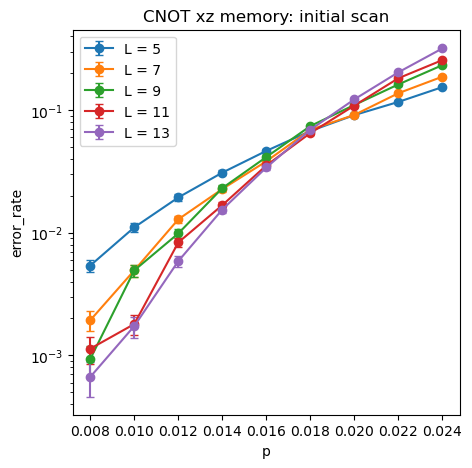

In [2]:
initial_scan = load_memory_scan(
    PROJECT_DIR / "results/cnot_primitive_xz/stage1/memory_T1d",
    p_values=[0.008, 0.010, 0.012, 0.014, 0.016, 0.018, 0.020, 0.022, 0.024],
    L_values=[5, 7, 9, 11, 13],
    label="XZ memory initial scan",
)
initial_scan.print_summary()
plot_rate_scan(
    initial_scan,
    title="CNOT xz memory: initial scan",
    ylabel="error_rate",
)

## Full scan
### Overall error rate
`T = d` and `T = 2d`, a fixed `10^5` trials per point (`jobs/cnot_primitive_xz_memory_full_scan.sh`). Each `T` is fitted with all sizes and without `L = 9`, which fails 4-11% more often than the geometric mean of `L = 7` and 11 (printed below) and makes the all-size fits fail the goodness-of-fit test.

Loaded 65 requested XZ memory T = d full scan files; ignored 0 files outside the requested lists
L values: [ 5  7  9 11 13]
p values: [0.009 0.012 0.014 0.015 0.016 0.017 0.018 0.019 0.02  0.021 0.022 0.023
 0.027]
repeat counts:
 [[1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1]]


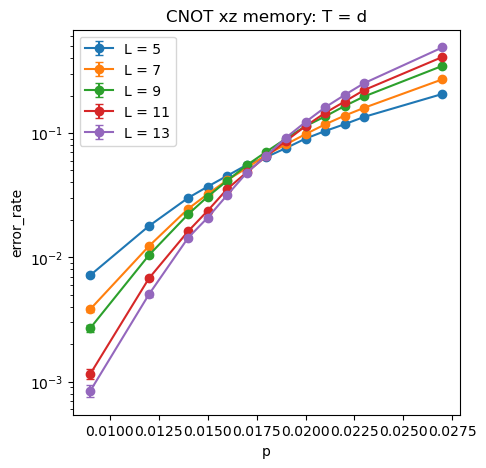

#### Finite-size scaling fit: XZ memory full scan — T = d, all L

Degree-2 model: $P_L(p)=A+Bx+Cx^{2}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.016, 0.020]$ and $L \in [5, 7, 9, 11, 13]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.01786(5) |
| $p_c$ (%) | 1.786(5) |
| $\nu$ | 1.39(4) |
| $A$ | 0.0643(7) |
| $B$ | 3.4(2) |
| $C$ | 66(7) |
| $\chi^2 / \mathrm{dof}$ | 190.87 / 20 = 9.54 |
| goodness-of-fit $p$-value | 7.12e-30 |

> **Fit-quality warning:** the degree-2 scaling model is rejected at the 5% level for this window. The covariance errors are statistical only; vary the degree, fit window, and minimum $L$ before quoting a final uncertainty.

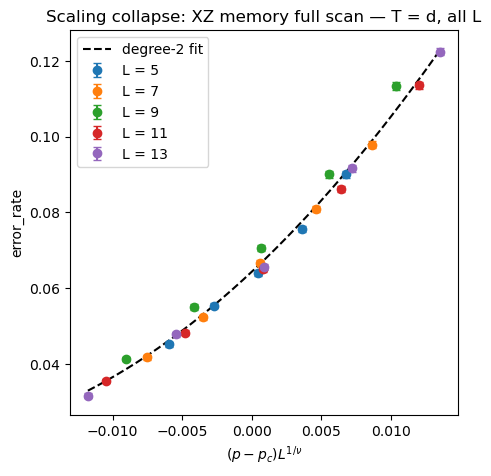

#### Finite-size scaling fit: XZ memory full scan — T = d, without L = 9

Degree-2 model: $P_L(p)=A+Bx+Cx^{2}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.016, 0.020]$ and $L \in [5, 7, 11, 13]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.01788(5) |
| $p_c$ (%) | 1.788(5) |
| $\nu$ | 1.36(4) |
| $A$ | 0.0637(7) |
| $B$ | 3.3(2) |
| $C$ | 63(7) |
| $\chi^2 / \mathrm{dof}$ | 19.65 / 15 = 1.31 |
| goodness-of-fit $p$-value | 0.186 |

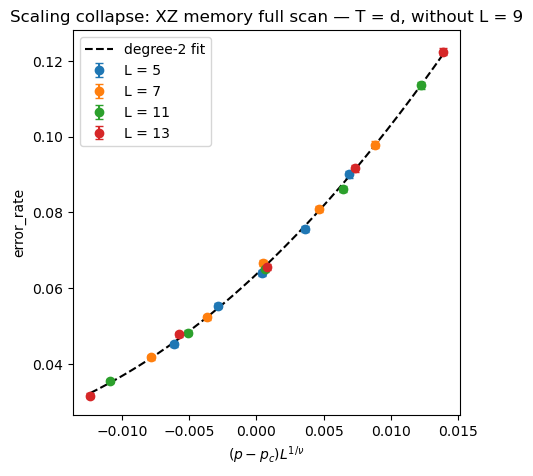

Loaded 65 requested XZ memory T = 2d full scan files; ignored 0 files outside the requested lists
L values: [ 5  7  9 11 13]
p values: [0.009 0.012 0.014 0.015 0.016 0.017 0.018 0.019 0.02  0.021 0.022 0.023
 0.027]
repeat counts:
 [[1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1]]


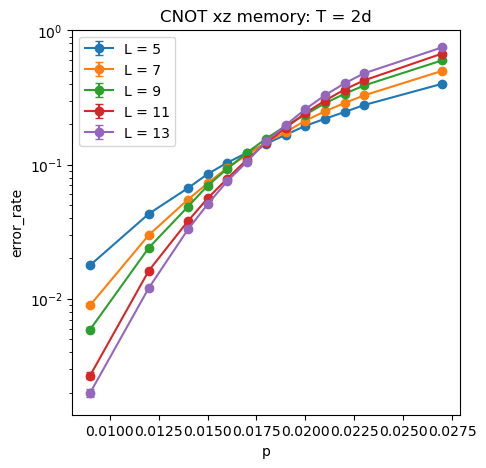

#### Finite-size scaling fit: XZ memory full scan — T = 2d, all L

Degree-2 model: $P_L(p)=A+Bx+Cx^{2}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.016, 0.020]$ and $L \in [5, 7, 9, 11, 13]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.01785(3) |
| $p_c$ (%) | 1.785(3) |
| $\nu$ | 1.40(3) |
| $A$ | 0.142(1) |
| $B$ | 7.2(2) |
| $C$ | 117(9) |
| $\chi^2 / \mathrm{dof}$ | 291.60 / 20 = 14.58 |
| goodness-of-fit $p$-value | 4.19e-50 |

> **Fit-quality warning:** the degree-2 scaling model is rejected at the 5% level for this window. The covariance errors are statistical only; vary the degree, fit window, and minimum $L$ before quoting a final uncertainty.

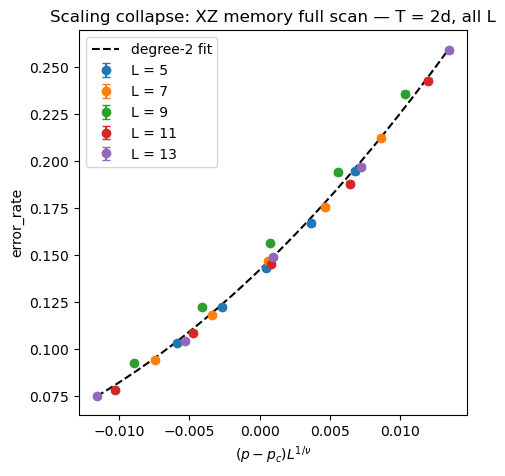

#### Finite-size scaling fit: XZ memory full scan — T = 2d, without L = 9

Degree-2 model: $P_L(p)=A+Bx+Cx^{2}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.016, 0.020]$ and $L \in [5, 7, 11, 13]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.01788(3) |
| $p_c$ (%) | 1.788(3) |
| $\nu$ | 1.39(3) |
| $A$ | 0.141(1) |
| $B$ | 7.1(3) |
| $C$ | 121(10) |
| $\chi^2 / \mathrm{dof}$ | 21.12 / 15 = 1.41 |
| goodness-of-fit $p$-value | 0.133 |

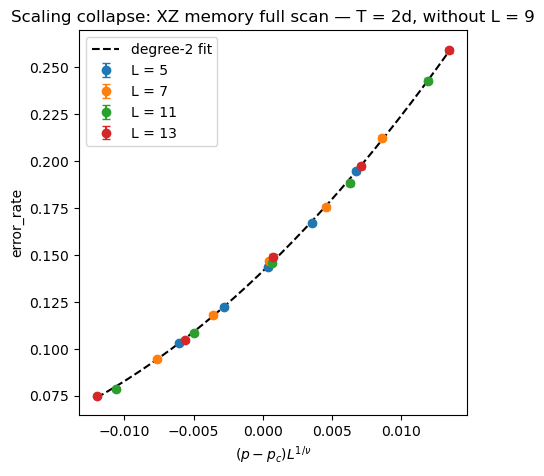

T = d, P(L = 9) / sqrt(P(L = 7) P(L = 11)): p = 0.009: 1.28, p = 0.012: 1.14, p = 0.014: 1.11, p = 0.015: 1.11, p = 0.016: 1.07, p = 0.017: 1.10, p = 0.018: 1.07, p = 0.019: 1.08, p = 0.02: 1.08, p = 0.021: 1.04, p = 0.022: 1.05, p = 0.023: 1.05, p = 0.027: 1.04


In [3]:
# Full scan
DATA_DIR = PROJECT_DIR / "results/cnot_primitive_xz/memory"
full_L_values = [5, 7, 9, 11, 13]
full_p_values = [0.009, 0.012, 0.014, 0.015, 0.016, 0.017, 0.018, 0.019, 0.020, 0.021, 0.022, 0.023, 0.027]

# Select the exact p and L groups used by every fit.
fit_p_values = [0.016, 0.017, 0.018, 0.019, 0.020]
fit_L_groups = {"all L": [5, 7, 9, 11, 13], "without L = 9": [5, 7, 11, 13]}
fit_degree = 2

full_scans = {}
full_fits = []
for factor in (1, 2):
    tag = "T = d" if factor == 1 else f"T = {factor}d"
    full_scans[factor] = load_memory_scan(DATA_DIR / f"T{factor}d", full_p_values, full_L_values, f"XZ memory {tag} full scan")
    full_scans[factor].print_summary()
    plot_rate_scan(
        full_scans[factor],
        title=f"CNOT xz memory: {tag}",
        ylabel="error_rate",
    )
    for group, fit_L_values in fit_L_groups.items():
        fit_scan = load_memory_scan(DATA_DIR / f"T{factor}d", fit_p_values, fit_L_values, f"XZ memory {tag} fit")
        fit = fit_finite_size_scaling(
            fit_scan,
            label=f"XZ memory full scan — {tag}, {group}",
            polynomial_degree=fit_degree,
            fit_p_range=(min(fit_p_values), max(fit_p_values)),
            min_L=min(fit_L_values),
        )
        full_fits.append(fit)
        display_finite_size_scaling_fit(fit, "error_rate")

rate = full_scans[1].rate().values
ratio = rate[2] / np.sqrt(rate[1] * rate[3])
print("T = d, P(L = 9) / sqrt(P(L = 7) P(L = 11)):", ", ".join(f"p = {p}: {r:.2f}" for p, r in zip(full_p_values, ratio)))

### Error rate per round
`P(T) = P_max [1 - B (1 - eps / P_max)^T]` over `T = d, 2d` (`P_max = 15/16`), and `Lambda` from `ln eps` against `(L + 1)/2`.

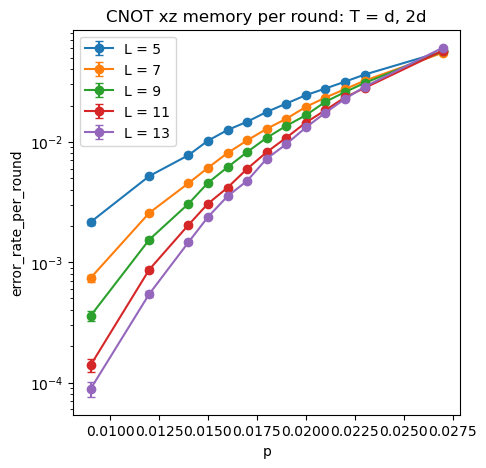

p = 0.009: Lambda = 2.36 ± 0.07
p = 0.012: Lambda = 1.77 ± 0.02
p = 0.014: Lambda = 1.52 ± 0.01
p = 0.016: Lambda = 1.38 ± 0.01
p = 0.018: Lambda = 1.25 ± 0.01
p = 0.020: Lambda = 1.16 ± 0.01
p = 0.023: Lambda = 1.06 ± 0.00
p = 0.027: Lambda = 0.98 ± 0.00


In [4]:
eps = np.full((len(full_L_values), len(full_p_values)), np.nan)
eps_err = np.full_like(eps, np.nan)
for i, L in enumerate(full_L_values):
    for j in range(len(full_p_values)):
        trials = [full_scans[factor].trials[i, j] for factor in (1, 2)]
        failures = [full_scans[factor].rate().values[i, j] * t for factor, t in zip((1, 2), trials)]
        fit = fit_decay_rate([L, 2 * L], failures, trials, p_max=P_MAX_BLOCK)
        eps[i, j], eps_err[i, j] = fit.eps, fit.eps_error
per_round = rates_as_scan({"overall": RateEstimate(eps, eps_err)}, L_values=full_L_values, p_values=full_p_values, label="per round")
plot_rate_scan(
    per_round,
    title="CNOT xz memory per round: T = d, 2d",
    ylabel="error_rate_per_round",
)
for j, p in enumerate(full_p_values):
    if p in (0.009, 0.012, 0.014, 0.016, 0.018, 0.020, 0.023, 0.027):
        lam = fit_lambda(full_L_values, eps[:, j], eps_err[:, j])
        print(f"p = {p:.3f}: Lambda = {lam.Lambda:.2f} ± {lam.Lambda_error:.2f}")

In [5]:
display_fit_summary(
    full_fits,
    title="XZ memory full-scan fit summary",
)

## XZ memory full-scan fit summary

| Timing and block | degree | $p_c$ | $p_c$ (%) | $\nu$ | $\chi^2 / \mathrm{dof}$ | fit $p$-value |
|---|---:|---:|---:|---:|---:|---:|
| XZ memory full scan — T = d, all L | 2 | 0.01786(5) | 1.786(5) | 1.39(4) | 9.54 | 7.12e-30 |
| XZ memory full scan — T = d, without L = 9 | 2 | 0.01788(5) | 1.788(5) | 1.36(4) | 1.31 | 0.186 |
| XZ memory full scan — T = 2d, all L | 2 | 0.01785(3) | 1.785(3) | 1.40(3) | 14.58 | 4.19e-50 |
| XZ memory full scan — T = 2d, without L = 9 | 2 | 0.01788(3) | 1.788(3) | 1.39(3) | 1.41 | 0.133 |